In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/vasudevdinesh/youtube-2/raw_sources.csv
/kaggle/input/datasets/vasudevdinesh/youtube-2/audio/Energy_1.0/yt_batch2_001.wav
/kaggle/input/datasets/vasudevdinesh/youtube-2/audio/Energy_1.0/yt_batch2_002.wav
/kaggle/input/datasets/vasudevdinesh/youtube-2/audio/Energy_1.0/yt_batch2_003.wav
/kaggle/input/datasets/vasudevdinesh/youtube-2/audio/K10/yt_batch2_012.wav
/kaggle/input/datasets/vasudevdinesh/youtube-2/audio/K10/yt_batch2_013.wav
/kaggle/input/datasets/vasudevdinesh/youtube-2/audio/K10/yt_batch2_014.wav
/kaggle/input/datasets/vasudevdinesh/youtube-2/audio/K10/yt_batch2_015.wav
/kaggle/input/datasets/vasudevdinesh/youtube-2/audio/K12_1.2_NA/yt_batch2_016.wav
/kaggle/input/datasets/vasudevdinesh/youtube-2/audio/K12_1.2_NA/yt_batch2_017.wav
/kaggle/input/datasets/vasudevdinesh/youtube-2/audio/K12_1.2_NA/yt_batch2_018.wav
/kaggle/input/datasets/vasudevdinesh/youtube-2/audio/K12_1.2_NA/yt_batch2_019.wav
/kaggle/input/datasets/vasudevdinesh/youtube-2/audio/Revotron_1

# 1. Project Overview

**This project explores the application of deep learning techniques for identifying engine characteristics from vehicle audio recordings.The objective is to develop an audio-based classification system capable of identifying multiple engine attributes, including cylinder configuration, fuel type, turbocharging status, engine starting condition, and engine family.The proposed approach combines audio preprocessing, transfer learning using ResNet34, and multi-task learning to extract meaningful acoustic representations from engine sounds.**


In [2]:
import os, glob
import numpy as np
import pandas as pd
import librosa
import torch
from sklearn.utils.class_weight import compute_class_weight

TARGET_SR = 32000
WIN_SEC = 3.0
WIN_LEN = int(TARGET_SR * WIN_SEC)

# 1. AUTO-DISCOVER AND MERGE BOTH DATASETS
csv_paths = glob.glob("/kaggle/input/**/raw_sources.csv", recursive=True)
print(f"Found {len(csv_paths)} dataset manifests:", csv_paths)

dfs = []
for cpath in csv_paths:
    base_dir = os.path.dirname(cpath)
    df_part = pd.read_csv(cpath)
    df_part["full_wav_path"] = df_part["wav_path"].apply(lambda p: os.path.join(base_dir, p))
    dfs.append(df_part)

df_master = pd.concat(dfs, ignore_index=True)
df_master = df_master[df_master["full_wav_path"].apply(os.path.exists)].reset_index(drop=True)

# 2. ENCODE MULTI-HEAD TARGETS (WITH -1 FOR MISSING/UNKNOWN LABELS)
fuel_map = {"Petrol": 0, "Diesel": 1}
cyl_map = {3: 0, 4: 1}
state_map = {"warm": 0, "cold": 1, "unknown": -1}

df_master["label_fuel"] = df_master["fuel_type"].str.capitalize().map(fuel_map).fillna(-1).astype(int)
df_master["label_cyl"] = df_master["cylinders"].map(cyl_map).fillna(-1).astype(int)
df_master["label_turbo"] = df_master["is_turbo"].fillna(-1).astype(int)
df_master["label_state"] = df_master["start_state"].str.lower().map(state_map).fillna(-1).astype(int)

# Group Engine Families: only train on families with >= 2 distinct cars; set ultra-rare ones to -1
fam_counts = df_master.groupby("engine_family")["car_instance_id"].nunique()
valid_fams = sorted(fam_counts[fam_counts >= 2].index.tolist())
fam_map = {f: i for i, f in enumerate(valid_fams)}
df_master["label_family"] = df_master["engine_family"].map(fam_map).fillna(-1).astype(int)

print(f"\nMerged {len(df_master)} total recordings:")
print(f" - Cylinders: 3-Cyl={(df_master['label_cyl']==0).sum()} | 4-Cyl={(df_master['label_cyl']==1).sum()}")
print(f" - Turbo:     NA={(df_master['label_turbo']==0).sum()} | Turbo={(df_master['label_turbo']==1).sum()}")
print(f" - Fuel:      Petrol={(df_master['label_fuel']==0).sum()} | Diesel={(df_master['label_fuel']==1).sum()}")
print(f" - Valid Engine Families ({len(valid_fams)}): {valid_fams}")

# 3. SLICE RECORDINGS INTO 3.0s WINDOWS (MULTIPLIES TRAINING SAMPLES)
window_rows = []
for _, row in df_master.iterrows():
    y, _ = librosa.load(row["full_wav_path"], sr=TARGET_SR, mono=True)
    # Extract non-overlapping 3-second chunks (up to 4 chunks per recording so long clips don't dominate)
    num_wins = min(len(y) // WIN_LEN, 4)
    for w_idx in range(max(1, num_wins)):
        start_sample = w_idx * WIN_LEN
        r_dict = row.to_dict()
        r_dict["start_sample"] = start_sample
        window_rows.append(r_dict)

df_windows = pd.DataFrame(window_rows)
print(f"Expanded {len(df_master)} recordings into {len(df_windows)} 3.0s spectrogram windows!")

Found 3 dataset manifests: ['/kaggle/input/datasets/vasudevdinesh/youtube-2/raw_sources.csv', '/kaggle/input/datasets/vasudevdinesh/youtube-scraped-specs-zip/raw_sources.csv', '/kaggle/input/datasets/vasudevdinesh/parking-lot-real-cars/raw_sources.csv']

Merged 84 total recordings:
 - Cylinders: 3-Cyl=35 | 4-Cyl=49
 - Turbo:     NA=54 | Turbo=30
 - Fuel:      Petrol=62 | Diesel=22
 - Valid Engine Families (12): ['D13A_1.3_DDiS', 'EA211_1.0_TSI', 'Energy_1.0', 'K10', 'K12N_1.2_NA', 'K12_1.2_NA', 'K15', 'Kappa_1.0_Turbo', 'L15Z_1.5_iVTEC', 'Revotron_1.2_NA', 'i-VTEC_1.2', 'mHawk_2.2_Diesel']
Expanded 84 recordings into 313 3.0s spectrogram windows!


# 2. Dataset Collection and Preparation


**The project uses multiple sources of real-world vehicle engine recordings. These datasets are consolidated into a unified dataset, with corresponding metadata and labels.Audio recordings are processed into fixed-duration segments to provide consistent inputs to the deep learning model**
.

In [3]:
import numpy as np
import librosa
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

TARGET_SR = 32000
WIN_LEN = int(TARGET_SR * 3.0)

class EngineAudioDataset(Dataset):
    def __init__(self, df, is_train=True):
        self.df = df.reset_index(drop=True)
        self.is_train = is_train

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        y, _ = librosa.load(row["full_wav_path"], sr=TARGET_SR, mono=True)
        
        start = int(row["start_sample"])
        if len(y) >= start + WIN_LEN:
            y_win = y[start : start + WIN_LEN]
        else:
            y_win = np.pad(y, (0, max(0, WIN_LEN - len(y))), mode="wrap")[:WIN_LEN]

        # Physics-Safe Waveform Augmentations
        if self.is_train:
            y_win = y_win * np.random.uniform(0.7, 1.3)
            if np.random.rand() < 0.5:
                y_win = y_win + np.random.normal(0, 0.003, size=len(y_win)).astype(np.float32)

        # Widen fmax to 14,000 Hz to capture high-pitched Turbo compressor whistle
        mel = librosa.feature.melspectrogram(
            y=y_win, sr=TARGET_SR, n_fft=2048, hop_length=512,
            n_mels=128, fmin=15.0, fmax=14000.0, power=2.0
        )
        log_mel = librosa.power_to_db(mel, ref=np.max)
        log_mel = (log_mel - log_mel.mean()) / (log_mel.std() + 1e-6)

        # SpecAugment
        if self.is_train:
            if np.random.rand() < 0.5:
                f_mask = np.random.randint(4, 14)
                f0 = np.random.randint(0, 128 - f_mask)
                log_mel[f0:f0+f_mask, :] = 0.0
            if np.random.rand() < 0.5:
                t_mask = np.random.randint(4, 20)
                t0 = np.random.randint(0, log_mel.shape[1] - t_mask)
                log_mel[:, t0:t0+t_mask] = 0.0

        spec_tensor = torch.tensor(log_mel, dtype=torch.float32).unsqueeze(0).repeat(3, 1, 1)

        labels = {
            "fuel": torch.tensor(int(row["label_fuel"]), dtype=torch.long),
            "cyl": torch.tensor(int(row["label_cyl"]), dtype=torch.long),
            "turbo": torch.tensor(int(row["label_turbo"]), dtype=torch.long),
            "state": torch.tensor(int(row["label_state"]), dtype=torch.long),
            "family": torch.tensor(int(row["label_family"]), dtype=torch.long),
        }
        return spec_tensor, labels

In [12]:
import os, urllib.request, zipfile, glob
import pandas as pd

TMP_DIR = "/kaggle/working/zenodo_audio"
os.makedirs(TMP_DIR, exist_ok=True)

# 1. Download & Extract Zenodo Tier 1 Dataset (Petrol vs Diesel)
zenodo_urls = {
    "Diesel": "https://zenodo.org/records/18777405/files/Diesel%20Motor%20Sounds.zip?download=1",
    "Petrol": "https://zenodo.org/records/18777405/files/Petrol%20Motor%20Sounds.zip?download=1"
}

for fuel, url in zenodo_urls.items():
    out_folder = f"{TMP_DIR}/{fuel}"
    if not os.path.exists(out_folder) or len(os.listdir(out_folder)) == 0:
        print(f"Downloading Zenodo {fuel} idle recordings...")
        os.makedirs(out_folder, exist_ok=True)
        zpath = f"{TMP_DIR}/{fuel}.zip"
        urllib.request.urlretrieve(url, zpath)
        with zipfile.ZipFile(zpath, "r") as zf:
            zf.extractall(out_folder)

# 2. Build the Zenodo Manifest
zenodo_records = []
for fuel in ["Diesel", "Petrol"]:
    for wav_p in glob.glob(f"{TMP_DIR}/{fuel}/**/*.wav", recursive=True):
        # We assign a unique ID so StratifiedGroupKFold keeps all windows of this file together
        rec_id = f"zenodo_{fuel}_{os.path.splitext(os.path.basename(wav_p))[0]}"
        zenodo_records.append({
            "recording_id": rec_id,
            "car_instance_id": rec_id, 
            "full_wav_path": wav_p,
            "label_fuel": 1 if fuel == "Diesel" else 0,
            "label_cyl": -1,   # IGNORE INDEX triggers here
            "label_turbo": -1, # IGNORE INDEX triggers here
            "label_state": -1,
            "label_family": -1
        })

df_zenodo = pd.DataFrame(zenodo_records)

# 3. Slice Zenodo into 3-second windows just like df_master
zenodo_windows = []
WIN_LEN = int(32000 * 3.0)
for _, row in df_zenodo.iterrows():
    # Only grab the first 3 windows (9 seconds) so Zenodo doesn't overwhelmingly dominate the dataset size
    try:
        y, _ = librosa.load(row["full_wav_path"], sr=32000, mono=True, duration=9.0)
        num_wins = max(1, len(y) // WIN_LEN)
        for w_idx in range(num_wins):
            r_dict = row.to_dict()
            r_dict["start_sample"] = w_idx * WIN_LEN
            zenodo_windows.append(r_dict)
    except Exception:
        pass

df_zenodo_wins = pd.DataFrame(zenodo_windows)

# 4. Merge with your existing df_windows (from Cell 1)
df_windows = pd.concat([df_windows, df_zenodo_wins], ignore_index=True)

print(f"Successfully injected {len(df_zenodo_wins)} Zenodo Fuel windows into the training pipeline!")
print(f"Total Training Windows: {len(df_windows)}")

Successfully injected 320 Zenodo Fuel windows into the training pipeline!
Total Training Windows: 633


# 3. Exploratory Data Analysis

**Before model development, the dataset is examined to understand its composition, class distributions, engine family representation, and relationships between available target variables.**

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

sns.set_theme(style="whitegrid", palette="viridis")

# 1. Dataset overview
print("=" * 55)
print("             DATASET OVERVIEW")
print("=" * 55)

print(f"Total original recordings : {len(df_master)}")
print(f"Total 3-second windows    : {len(df_windows)}")
print(f"Unique car instances      : {df_master['car_instance_id'].nunique()}")
print(f"Unique engine families    : {df_master['engine_family'].nunique()}")
print(f"Sampling rate             : {TARGET_SR} Hz")
print(f"Window duration           : {WIN_SEC} seconds")

print("\nDataset columns:")
print(df_master.columns.tolist())

print("\nMissing values:")
display(df_master.isnull().sum().sort_values(ascending=False).to_frame("Missing Values"))

             DATASET OVERVIEW
Total original recordings : 84
Total 3-second windows    : 313
Unique car instances      : 65
Unique engine families    : 31
Sampling rate             : 32000 Hz
Window duration           : 3.0 seconds

Dataset columns:
['recording_id', 'car_instance_id', 'wav_path', 'car_model', 'engine_family', 'fuel_type', 'cylinders', 'is_turbo', 'start_state', 'dataset_source', 'full_wav_path', 'label_fuel', 'label_cyl', 'label_turbo', 'label_state', 'label_family']

Missing values:


,Missing Values
recording_id,0
car_instance_id,0
wav_path,0
car_model,0
engine_family,0
fuel_type,0
cylinders,0
is_turbo,0
start_state,0
dataset_source,0


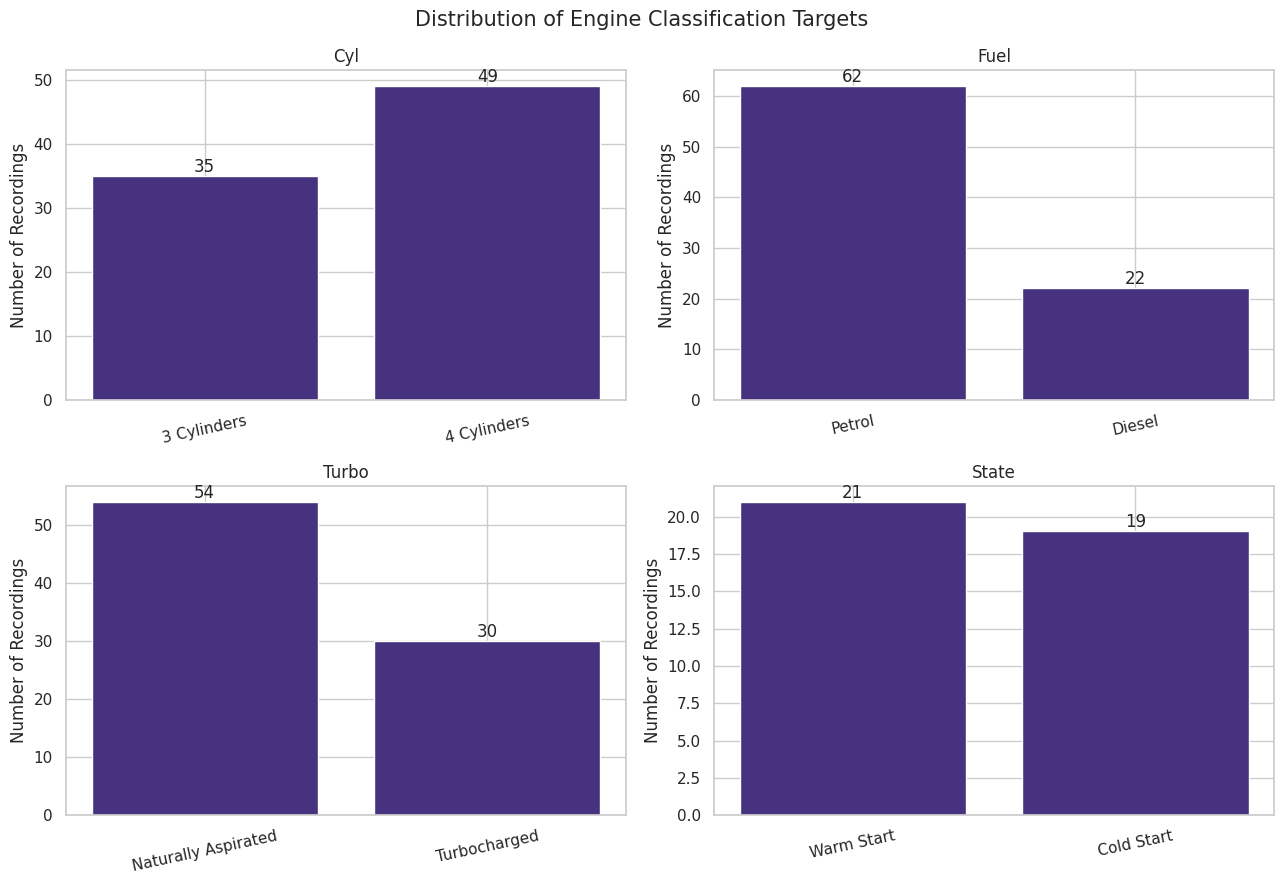

In [5]:
# Target distributions at recording level (not window level)

target_columns = {
    "label_cyl": {0: "3 Cylinders", 1: "4 Cylinders"},
    "label_fuel": {0: "Petrol", 1: "Diesel"},
    "label_turbo": {0: "Naturally Aspirated", 1: "Turbocharged"},
    "label_state": {0: "Warm Start", 1: "Cold Start"}
}

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
axes = axes.flatten()

for ax, (column, labels) in zip(axes, target_columns.items()):

    counts = df_master[column].value_counts().reindex(labels.keys(), fill_value=0)

    bars = ax.bar(
        [labels[k] for k in labels],
        counts.values
    )

    ax.set_title(column.replace("label_", "").replace("_", " ").title())
    ax.set_ylabel("Number of Recordings")
    ax.tick_params(axis="x", rotation=12)

    for bar, count in zip(bars, counts.values):
        ax.text(
            bar.get_x() + bar.get_width()/2,
            bar.get_height(),
            str(count),
            ha="center",
            va="bottom"
        )

plt.suptitle("Distribution of Engine Classification Targets", fontsize=15)
plt.tight_layout()
plt.show()

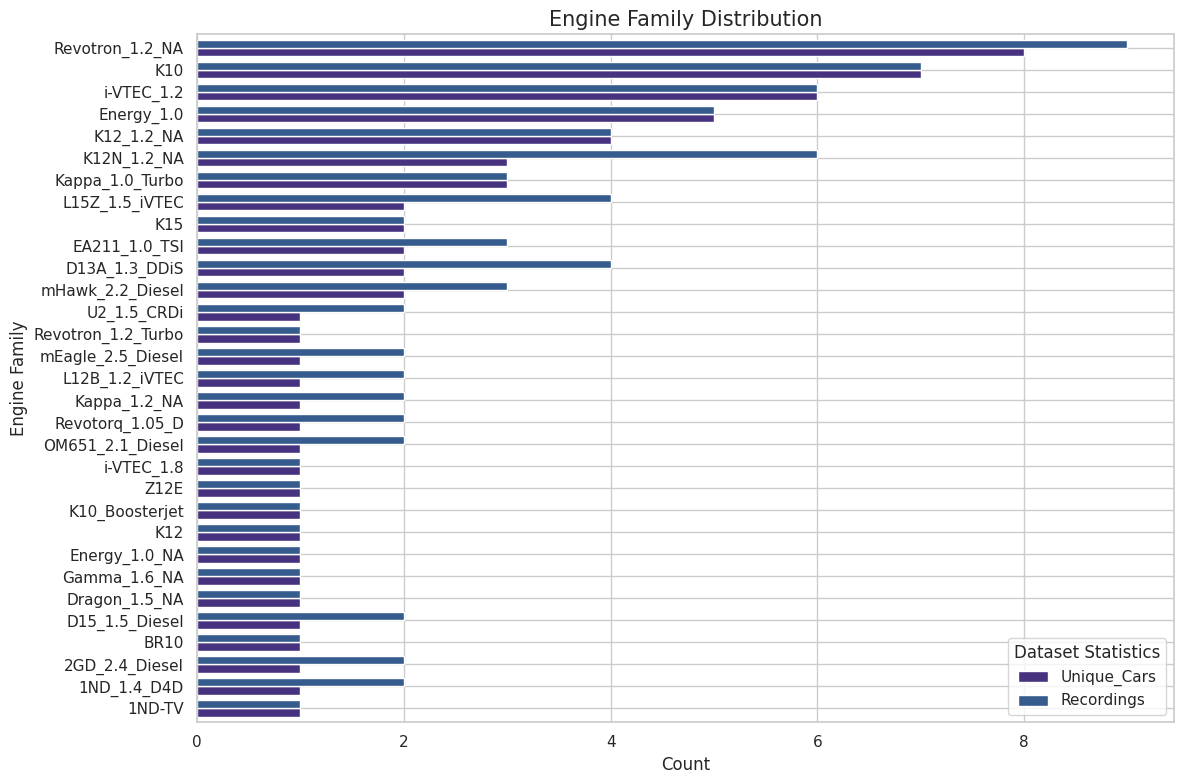

,Unique_Cars,Recordings
engine_family,,
Revotron_1.2_NA,8,9
K10,7,7
i-VTEC_1.2,6,6
Energy_1.0,5,5
K12_1.2_NA,4,4
Kappa_1.0_Turbo,3,3
K12N_1.2_NA,3,6
K15,2,2
EA211_1.0_TSI,2,3


In [6]:
# Count unique cars and recordings per engine family

family_stats = (
    df_master.groupby("engine_family")
    .agg(
        Unique_Cars=("car_instance_id", "nunique"),
        Recordings=("recording_id", "nunique")
    )
    .sort_values("Unique_Cars", ascending=True)
)

fig, ax = plt.subplots(figsize=(12, 8))

family_stats.plot(
    kind="barh",
    ax=ax,
    width=0.75
)

ax.set_title("Engine Family Distribution", fontsize=15)
ax.set_xlabel("Count")
ax.set_ylabel("Engine Family")
ax.legend(title="Dataset Statistics")

plt.tight_layout()
plt.show()

display(family_stats.sort_values("Unique_Cars", ascending=False))

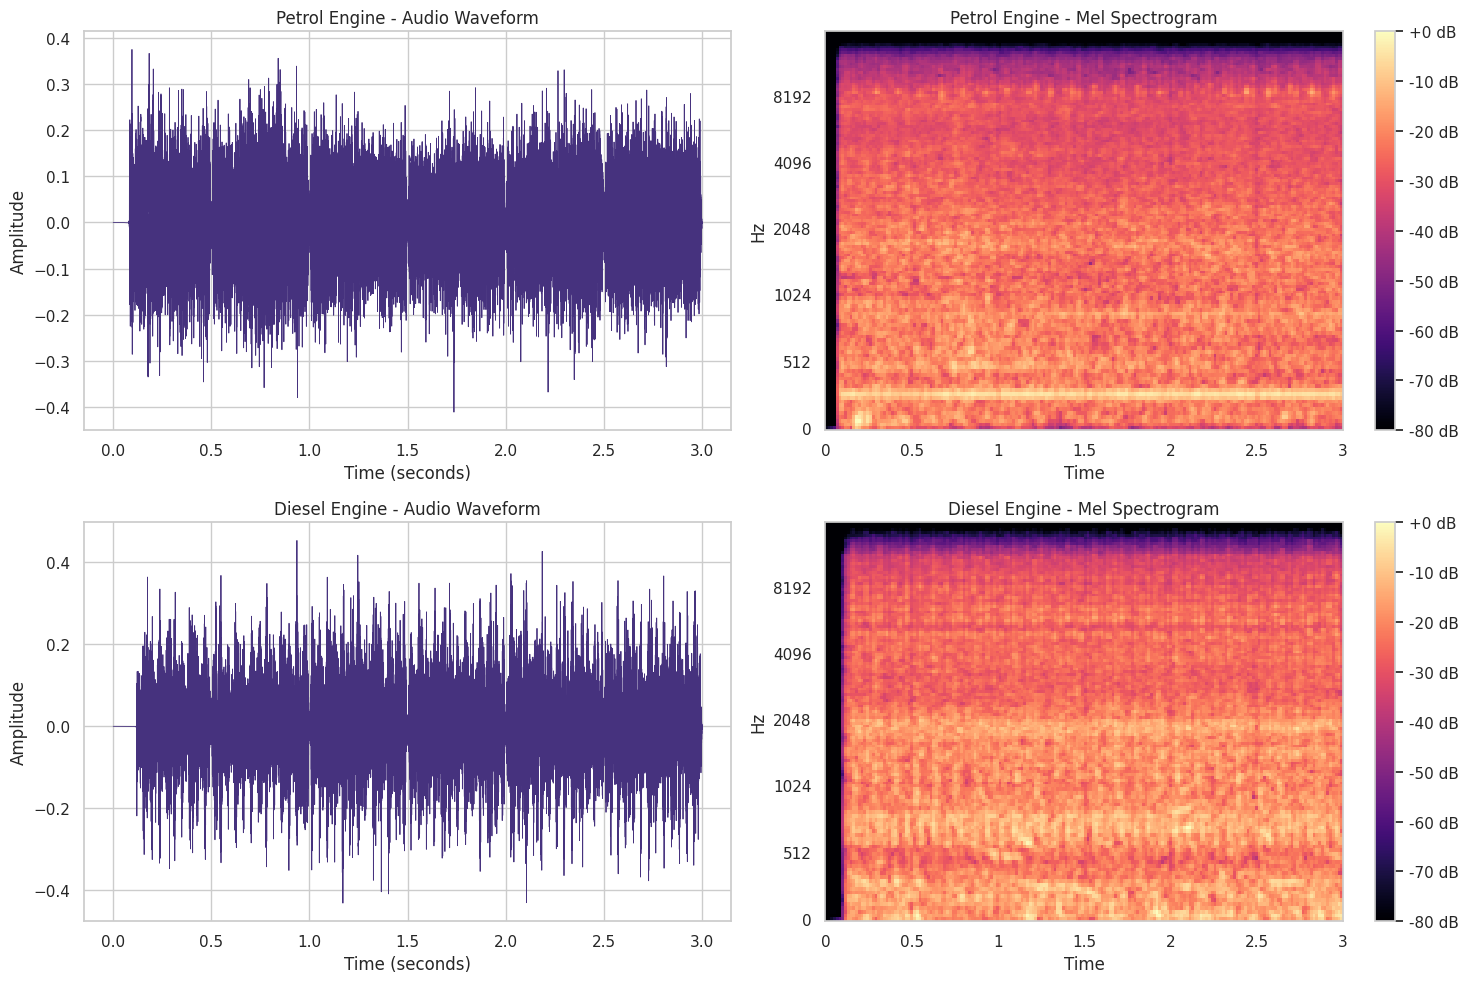

In [7]:
import librosa.display

# Select one recording from each fuel category
sample_records = {}

for fuel_name, fuel_label in [("Petrol", 0), ("Diesel", 1)]:

    subset = df_master[df_master["label_fuel"] == fuel_label]

    if len(subset) > 0:
        sample_records[fuel_name] = subset.iloc[0]

fig, axes = plt.subplots(len(sample_records), 2, figsize=(15, 5 * len(sample_records)))

if len(sample_records) == 1:
    axes = np.array([axes])

for i, (fuel_name, row) in enumerate(sample_records.items()):

    y, sr = librosa.load(
        row["full_wav_path"],
        sr=TARGET_SR,
        mono=True,
        duration=WIN_SEC
    )

    time_axis = np.arange(len(y)) / sr

    # Waveform
    axes[i, 0].plot(time_axis, y, linewidth=0.6)
    axes[i, 0].set_title(f"{fuel_name} Engine - Audio Waveform")
    axes[i, 0].set_xlabel("Time (seconds)")
    axes[i, 0].set_ylabel("Amplitude")

    # Mel Spectrogram
    mel = librosa.feature.melspectrogram(
        y=y,
        sr=sr,
        n_fft=2048,
        hop_length=512,
        n_mels=128,
        fmin=15,
        fmax=14000,
        power=2.0
    )

    mel_db = librosa.power_to_db(mel, ref=np.max)

    img = librosa.display.specshow(
        mel_db,
        sr=sr,
        hop_length=512,
        x_axis="time",
        y_axis="mel",
        ax=axes[i, 1],
        cmap="magma"
    )

    axes[i, 1].set_title(f"{fuel_name} Engine - Mel Spectrogram")
    fig.colorbar(img, ax=axes[i, 1], format="%+2.0f dB")

plt.tight_layout()
plt.show()

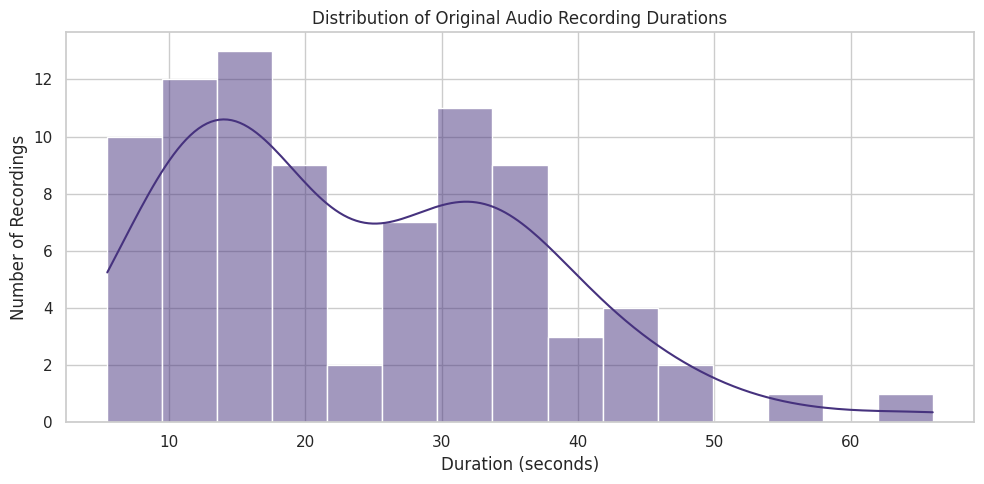

,Duration (seconds)
count,84.000000
mean,23.976190
std,12.840285
min,5.500000
25%,13.500000
50%,19.750000
75%,33.500000
max,66.000000


In [13]:
import os, copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.models as models
from torch.utils.data import DataLoader
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import f1_score, accuracy_score
from IPython.display import FileLink, display

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SAVE_PATH = "/kaggle/working/master_5head_engine_model.pth"

# 1. UNIFY ENGINE FAMILY NAMES ACROSS PARKING LOT, BATCH 1, AND BATCH 2 CSVs
FAMILY_ALIAS_MAP = {
    "L12B_1.2_iVTEC": "i-VTEC_1.2", "i-VTEC_1.2": "i-VTEC_1.2",
    "K12N_1.2_NA": "K12_1.2_NA", "K12": "K12_1.2_NA", "K12_1.2_NA": "K12_1.2_NA",
    "1ND_1.4_D4D": "1ND_1.4_D4D", "1ND-TV": "1ND_1.4_D4D",
    "Energy_1.0_NA": "Energy_1.0", "Energy_1.0": "Energy_1.0", "BR10": "Energy_1.0",
    "K10_Boosterjet": "K10",
}

df_indian = df_windows[df_windows["label_cyl"] != -1].copy().reset_index(drop=True)
df_zen_pool = df_windows[df_windows["label_cyl"] == -1].copy().reset_index(drop=True)

df_indian["engine_family"] = df_indian["engine_family"].astype(str).str.strip().replace(FAMILY_ALIAS_MAP)

fam_car_counts = df_indian.groupby("engine_family")["car_instance_id"].nunique()
valid_fams = sorted(fam_car_counts[fam_car_counts >= 2].index.tolist())
fam_map = {f: i for i, f in enumerate(valid_fams)}
inv_fam_map = {i: f for f, i in fam_map.items()}

df_indian["label_family"] = df_indian["engine_family"].map(fam_map).fillna(-1).astype(int)
df_zen_pool["label_family"] = -1

family_spec_lookup = {}
for fam_name, fam_idx in fam_map.items():
    sub = df_indian[df_indian["label_family"] == fam_idx].iloc[0]
    family_spec_lookup[fam_idx] = (int(sub["label_cyl"]), int(sub["label_fuel"]), int(sub["label_turbo"]))

# 2. CYLINDER-STRATIFIED SPLIT (Restored from the 92.3% model)
df_rare_indian = df_indian[df_indian["label_family"] == -1].copy()
df_valid_indian = df_indian[df_indian["label_family"] != -1].copy().reset_index(drop=True)

sgkf = StratifiedGroupKFold(n_splits=5)
# Split based on label_cyl to maximize physical accuracy
train_idx, val_idx = next(sgkf.split(df_valid_indian, df_valid_indian["label_cyl"], df_valid_indian["car_instance_id"]))

train_indian = pd.concat([df_valid_indian.iloc[train_idx], df_rare_indian], ignore_index=True)
val_df = df_valid_indian.iloc[val_idx].copy().reset_index(drop=True)

for f_idx in range(len(valid_fams)):
    if (val_df["label_family"] == f_idx).any() and not (train_indian["label_family"] == f_idx).any():
        car_to_move = val_df[val_df["label_family"] == f_idx]["car_instance_id"].iloc[0]
        move_rows = val_df[val_df["car_instance_id"] == car_to_move]
        train_indian = pd.concat([train_indian, move_rows], ignore_index=True)
        val_df = val_df[val_df["car_instance_id"] != car_to_move].reset_index(drop=True)

zen_petrol = df_zen_pool[df_zen_pool["label_fuel"] == 0].sample(n=min(100, (df_zen_pool["label_fuel"] == 0).sum()), random_state=42)
zen_diesel = df_zen_pool[df_zen_pool["label_fuel"] == 1].sample(n=min(100, (df_zen_pool["label_fuel"] == 1).sum()), random_state=42)
train_df = pd.concat([train_indian, zen_petrol, zen_diesel], ignore_index=True)

train_loader = DataLoader(EngineAudioDataset(train_df, is_train=True), batch_size=16, shuffle=True, drop_last=True)
val_loader = DataLoader(EngineAudioDataset(val_df, is_train=False), batch_size=16, shuffle=False)

# 3. 5-HEAD PRO ARCHITECTURE
class AttentionPool2d(nn.Module):
    def __init__(self, in_features):
        super().__init__()
        self.attn = nn.Sequential(
            nn.Conv2d(in_features, in_features // 4, kernel_size=1),
            nn.Tanh(), nn.Conv2d(in_features // 4, 1, kernel_size=1)
        )
    def forward(self, x):
        weights = F.softmax(self.attn(x).view(x.size(0), 1, -1), dim=-1)
        x_flat = x.view(x.size(0), x.size(1), -1)
        return torch.bmm(x_flat, weights.transpose(1, 2)).squeeze(-1)

class MultiHeadEngineResNetPro(nn.Module):
    def __init__(self, num_families):
        super().__init__()
        base = models.resnet34(weights=models.ResNet34_Weights.DEFAULT)
        for p in base.conv1.parameters(): p.requires_grad = False
        for p in base.bn1.parameters(): p.requires_grad = False
        for p in base.layer1.parameters(): p.requires_grad = False
        for p in base.layer2.parameters(): p.requires_grad = False

        self.feature_extractor = nn.Sequential(
            base.conv1, base.bn1, base.relu, base.maxpool,
            base.layer1, base.layer2, base.layer3, base.layer4
        )
        in_features = base.fc.in_features
        self.attn_pool = AttentionPool2d(in_features)
        self.bottleneck = nn.Sequential(
            nn.Linear(in_features, 256), nn.BatchNorm1d(256), nn.SiLU(), nn.Dropout(0.35)
        )
        self.head_cyl = nn.Linear(256, 2)
        self.head_fuel = nn.Linear(256, 2)
        self.head_turbo = nn.Linear(256, 2)
        self.head_state = nn.Linear(256, 2)
        self.head_family = nn.Linear(256 + 6, num_families)

    def forward(self, x):
        feat = self.bottleneck(self.attn_pool(self.feature_extractor(x)))
        out_cyl = self.head_cyl(feat)
        out_fuel = self.head_fuel(feat)
        out_turbo = self.head_turbo(feat)
        out_state = self.head_state(feat)
        
        fam_input = torch.cat([feat, out_cyl.detach(), out_fuel.detach(), out_turbo.detach()], dim=1)
        out_family = self.head_family(fam_input)
        return {"cyl": out_cyl, "fuel": out_fuel, "turbo": out_turbo, "state": out_state, "family": out_family}

def make_weighted_loss(series, num_classes):
    valid = series[series != -1].values
    classes = np.unique(valid)
    weights = np.ones(num_classes, dtype=np.float32)
    if len(classes) > 1:
        cw = compute_class_weight("balanced", classes=classes, y=valid)
        for c, w in zip(classes.astype(int), cw):
            weights[c] = w
    return nn.CrossEntropyLoss(weight=torch.tensor(weights).to(DEVICE), ignore_index=-1, label_smoothing=0.08)

model = MultiHeadEngineResNetPro(num_families=len(valid_fams)).to(DEVICE)

criterion = {
    "cyl": make_weighted_loss(train_df["label_cyl"], 2),
    "fuel": make_weighted_loss(train_df["label_fuel"], 2),
    "turbo": make_weighted_loss(train_df["label_turbo"], 2),
    "state": make_weighted_loss(train_df["label_state"], 2),
    "family": make_weighted_loss(train_df["label_family"], len(valid_fams)),
}

backbone_params = [p for p in model.feature_extractor.parameters() if p.requires_grad]
head_params = [p for n, p in model.named_parameters() if "feature_extractor" not in n and p.requires_grad]

optimizer = torch.optim.AdamW([
    {"params": backbone_params, "lr": 1e-4},
    {"params": head_params, "lr": 5e-4}
], weight_decay=2e-2)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=25)

best_cyl_score, best_ft_score, best_fam_score = -1.0, -1.0, -1.0
best_cyl_weights, best_ft_weights, best_fam_weights = None, None, None

for epoch in range(1, 26):
    model.train()
    total_loss = 0.0
    for x, y in train_loader:
        x = x.to(DEVICE)
        optimizer.zero_grad()
        out = model(x)
        
        loss = 0.0
        # Restored the exact loss weights from the 92.3% run
        head_weights = {"cyl": 1.5, "fuel": 1.2, "turbo": 1.2, "state": 0.6, "family": 1.2}
        for k, w in head_weights.items():
            target = y[k].to(DEVICE)
            if (target != -1).any():
                l = criterion[k](out[k], target)
                if not torch.isnan(l):
                    loss += w * l
                    
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=2.0)
        optimizer.step()
        total_loss += loss.item()
    scheduler.step()

    model.eval()
    probs = {k: [] for k in ["cyl", "fuel", "turbo", "state", "family"]}
    with torch.no_grad():
        for x, _ in val_loader:
            x = x.to(DEVICE)
            out = model(x)
            for k in probs.keys():
                probs[k].extend(F.softmax(out[k], dim=1).cpu().numpy())

    c_trues, c_preds, f_trues, f_preds, t_trues, t_preds, fam_trues, fam_preds = [], [], [], [], [], [], [], []
    for rec_id, group in val_df.groupby("recording_id"):
        idxs = group.index.tolist()
        r0 = group.iloc[0]
        
        p_cyl = np.mean([probs["cyl"][i] for i in idxs], axis=0)
        p_fuel = np.mean([probs["fuel"][i] for i in idxs], axis=0)
        p_turbo = np.mean([probs["turbo"][i] for i in idxs], axis=0)
        p_fam = np.mean([probs["family"][i] for i in idxs], axis=0)
        
        c_trues.append(int(r0["label_cyl"])); c_preds.append(int(p_cyl[1] >= 0.5))
        f_trues.append(int(r0["label_fuel"])); f_preds.append(int(p_fuel[1] >= 0.5))
        t_trues.append(int(r0["label_turbo"])); t_preds.append(int(p_turbo[1] >= 0.5))
        
        if int(r0["label_family"]) != -1:
            guided_fam = np.zeros_like(p_fam)
            for f_idx, (req_c, req_f, req_t) in family_spec_lookup.items():
                guided_fam[f_idx] = p_fam[f_idx] * p_cyl[req_c] * p_fuel[req_f] * p_turbo[req_t]
            fam_trues.append(int(r0["label_family"]))
            fam_preds.append(int(np.argmax(guided_fam)))

    cyl_f1 = f1_score(c_trues, c_preds, average="macro")
    cyl_acc = accuracy_score(c_trues, c_preds)
    fuel_acc = accuracy_score(f_trues, f_preds)
    turbo_acc = accuracy_score(t_trues, t_preds)
    fam_acc = accuracy_score(fam_trues, fam_preds) if len(fam_trues) > 0 else 0.0

    tags = []
    cyl_tiebreaker = cyl_f1 + 0.05 * (fuel_acc + turbo_acc)
    if cyl_tiebreaker > best_cyl_score:
        best_cyl_score = cyl_tiebreaker
        best_cyl_weights = copy.deepcopy(model.state_dict())
        tags.append("CYL")

    ft_score = fuel_acc + turbo_acc + 0.1 * cyl_f1
    if ft_score > best_ft_score:
        best_ft_score = ft_score
        best_ft_weights = copy.deepcopy(model.state_dict())
        tags.append("FUEL/TURBO")

    if fam_acc + 0.1 * cyl_f1 > best_fam_score:
        best_fam_score = fam_acc + 0.1 * cyl_f1
        best_fam_weights = copy.deepcopy(model.state_dict())
        tags.append("FAM")

    if tags:
        torch.save({
            "cyl_state_dict": best_cyl_weights,
            "ft_state_dict": best_ft_weights,
            "fam_state_dict": best_fam_weights,
            "valid_fams": valid_fams,
            "family_spec_lookup": family_spec_lookup
        }, SAVE_PATH)
        tag_str = f" [SAVED: {'+'.join(tags)}]"
    else:
        tag_str = ""

    print(f"Epoch {epoch:02d} | Loss:{total_loss/len(train_loader):.2f} | Cyl:{cyl_acc*100:5.1f}% (F1:{cyl_f1:.2f}) | Fuel:{fuel_acc*100:5.1f}% | Turbo:{turbo_acc*100:5.1f}% | Fam:{fam_acc*100:5.1f}%{tag_str}")

Epoch 01 | Loss:5.80 | Cyl: 69.2% (F1:0.69) | Fuel: 76.9% | Turbo: 53.8% | Fam: 15.4% [SAVED: CYL+FUEL/TURBO+FAM]
Epoch 02 | Loss:4.53 | Cyl: 61.5% (F1:0.58) | Fuel:100.0% | Turbo: 92.3% | Fam: 23.1% [SAVED: FUEL/TURBO+FAM]
Epoch 03 | Loss:3.49 | Cyl: 61.5% (F1:0.61) | Fuel: 92.3% | Turbo:100.0% | Fam: 23.1% [SAVED: FUEL/TURBO+FAM]
Epoch 04 | Loss:2.96 | Cyl: 53.8% (F1:0.51) | Fuel:100.0% | Turbo:100.0% | Fam: 23.1% [SAVED: FUEL/TURBO]
Epoch 05 | Loss:2.51 | Cyl: 46.2% (F1:0.46) | Fuel: 92.3% | Turbo: 92.3% | Fam:  7.7%
Epoch 06 | Loss:2.55 | Cyl: 61.5% (F1:0.61) | Fuel:100.0% | Turbo:100.0% | Fam: 23.1% [SAVED: FUEL/TURBO]
Epoch 07 | Loss:2.37 | Cyl: 61.5% (F1:0.62) | Fuel:100.0% | Turbo:100.0% | Fam:  7.7% [SAVED: FUEL/TURBO]
Epoch 08 | Loss:2.12 | Cyl: 53.8% (F1:0.46) | Fuel:100.0% | Turbo:100.0% | Fam: 30.8% [SAVED: FAM]
Epoch 09 | Loss:2.05 | Cyl: 53.8% (F1:0.51) | Fuel: 92.3% | Turbo:100.0% | Fam: 23.1%
Epoch 10 | Loss:2.07 | Cyl: 53.8% (F1:0.51) | Fuel: 92.3% | Turbo:100.0% | Fa

In [14]:
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from sklearn.metrics import accuracy_score, f1_score

# 1. Load the saved 5-head specialist models from disk
checkpoint = torch.load(SAVE_PATH, map_location=DEVICE, weights_only=False)
models_eval = {}
for k in ["cyl", "ft", "fam"]:
    m = MultiHeadEngineResNetPro(num_families=len(valid_fams)).to(DEVICE)
    m.load_state_dict(checkpoint[f"{k}_state_dict"])
    m.eval()
    models_eval[k] = m

family_spec_lookup = checkpoint["family_spec_lookup"]

def get_embeddings_and_probs(loader):
    probs = {"cyl": [], "fuel": [], "turbo": [], "state": [], "family": []}
    embeds = []
    with torch.no_grad():
        for x, _ in loader:
            x = x.to(DEVICE)
            m_fam = models_eval["fam"]
            feat_fam = m_fam.bottleneck(m_fam.attn_pool(m_fam.feature_extractor(x)))
            
            m_cyl = models_eval["cyl"]
            feat_cyl = m_cyl.bottleneck(m_cyl.attn_pool(m_cyl.feature_extractor(x)))
            
            combined_emb = torch.cat([F.normalize(feat_fam, p=2, dim=1), F.normalize(feat_cyl, p=2, dim=1)], dim=1)
            embeds.extend(combined_emb.cpu().numpy())

            probs["cyl"].extend(F.softmax(m_cyl(x)["cyl"], dim=1).cpu().numpy())
            out_ft = models_eval["ft"](x)
            probs["fuel"].extend(F.softmax(out_ft["fuel"], dim=1).cpu().numpy())
            probs["turbo"].extend(F.softmax(out_ft["turbo"], dim=1).cpu().numpy())
            probs["state"].extend(F.softmax(m_cyl(x)["state"], dim=1).cpu().numpy())
            probs["family"].extend(F.softmax(m_fam(x)["family"], dim=1).cpu().numpy())
            
    return probs, np.array(embeds)

# 2. Extract Embeddings & Remove Microphone Domain Bias (Parking Lot vs YouTube)
train_indian_loader = DataLoader(EngineAudioDataset(train_indian, is_train=False), batch_size=16, shuffle=False)
train_probs, train_embeds = get_embeddings_and_probs(train_indian_loader)
val_probs, val_embeds = get_embeddings_and_probs(val_loader)

is_park_train = train_indian["recording_id"].str.startswith("park_").values
is_park_val = val_df["recording_id"].str.startswith("park_").values

park_mean = np.mean(train_embeds[is_park_train], axis=0) if np.any(is_park_train) else 0.0
yt_mean = np.mean(train_embeds[~is_park_train], axis=0) if np.any(~is_park_train) else 0.0

train_embeds_centered = np.where(is_park_train[:, None], train_embeds - 0.5 * park_mean, train_embeds - 0.5 * yt_mean)
train_embeds_centered = train_embeds_centered / (np.linalg.norm(train_embeds_centered, axis=1, keepdims=True) + 1e-8)

val_embeds_centered = np.where(is_park_val[:, None], val_embeds - 0.5 * park_mean, val_embeds - 0.5 * yt_mean)
val_embeds_centered = val_embeds_centered / (np.linalg.norm(val_embeds_centered, axis=1, keepdims=True) + 1e-8)

# Build Domain-Centered Prototypes per Engine Family
family_prototypes = {}
for f_idx in range(len(valid_fams)):
    mask = (train_indian["label_family"].values == f_idx)
    if np.any(mask):
        proto = np.mean(train_embeds_centered[mask], axis=0)
        family_prototypes[f_idx] = proto / (np.linalg.norm(proto) + 1e-8)

# 3. Evaluate Validation Set with Hard Physical Gating + Domain-Centered Prototypes
records = []
for rec_id, group in val_df.groupby("recording_id"):
    idxs = group.index.tolist()
    r0 = group.iloc[0]
    
    p_cyl = np.mean([val_probs["cyl"][i] for i in idxs], axis=0)
    p_fuel = np.mean([val_probs["fuel"][i] for i in idxs], axis=0)
    p_turbo = np.mean([val_probs["turbo"][i] for i in idxs], axis=0)
    p_fam_raw = np.mean([val_probs["family"][i] for i in idxs], axis=0)
    
    rec_emb = np.mean(val_embeds_centered[idxs], axis=0)
    rec_emb = rec_emb / (np.linalg.norm(rec_emb) + 1e-8)
    
    pred_c = int(p_cyl[1] >= 0.5)
    pred_f = int(p_fuel[1] >= 0.5)
    pred_t = int(p_turbo[1] >= 0.5)

    guided_fam = np.zeros(len(valid_fams), dtype=np.float32)
    for f_idx, (req_c, req_f, req_t) in family_spec_lookup.items():
        cos_sim = np.dot(rec_emb, family_prototypes[f_idx]) if f_idx in family_prototypes else 0.0
        proto_score = np.exp(3.0 * cos_sim)
        # Combine raw head probability with prototype similarity (NO artificial small-family inflation)
        combined_score = (p_fam_raw[f_idx] ** 0.65) * (proto_score ** 0.35)
        
        # HARD PHYSICAL GATE (When physical spec confidence is high) + Soft Fallback
        spec_prob = p_cyl[req_c] * p_fuel[req_f] * p_turbo[req_t]
        if (req_c == pred_c) and (req_f == pred_f) and (req_t == pred_t):
            guided_fam[f_idx] = combined_score * (10.0 + 90.0 * spec_prob)
        else:
            guided_fam[f_idx] = combined_score * spec_prob

    pred_fam_idx = int(np.argmax(guided_fam))
    top2_fam_idxs = np.argsort(guided_fam)[-2:][::-1]
    true_fam_idx = int(r0["label_family"])

    records.append({
        "recording_id": rec_id, "car_model": r0["car_model"],
        "true_cyl": int(r0["label_cyl"]), "pred_cyl": pred_c,
        "true_fuel": int(r0["label_fuel"]), "pred_fuel": pred_f,
        "true_turbo": int(r0["label_turbo"]), "pred_turbo": pred_t,
        "true_fam_idx": true_fam_idx, "pred_fam_idx": pred_fam_idx,
        "top2_hit": (true_fam_idx in top2_fam_idxs) if true_fam_idx != -1 else False,
        "True_Fam": r0["engine_family"], "Pred_Fam": inv_fam_map.get(pred_fam_idx, "Unknown")
    })

df_all = pd.DataFrame(records)
df_known_fam = df_all[df_all["true_fam_idx"] != -1]

print("=== FINAL 5-HEAD DOMAIN-CENTERED + HARD-GATED REPORT CARD ===")
print(f"1. Cylinder Accuracy     : {accuracy_score(df_all['true_cyl'], df_all['pred_cyl'])*100:5.1f}% (Macro-F1: {f1_score(df_all['true_cyl'], df_all['pred_cyl'], average='macro'):.3f})")
print(f"2. Fuel Accuracy         : {accuracy_score(df_all['true_fuel'], df_all['pred_fuel'])*100:5.1f}%")
print(f"3. Turbo Accuracy        : {accuracy_score(df_all['true_turbo'], df_all['pred_turbo'])*100:5.1f}%")
print(f"4. Engine Family (Top-1) : {accuracy_score(df_known_fam['true_fam_idx'], df_known_fam['pred_fam_idx'])*100:5.1f}% | (Top-2 Match: {df_known_fam['top2_hit'].mean()*100:5.1f}%)\n")

df_all["Cyl"] = np.where(df_all["true_cyl"] == df_all["pred_cyl"], "✅", "❌")
df_all["Fuel"] = np.where(df_all["true_fuel"] == df_all["pred_fuel"], "✅", "❌")
df_all["Turbo"] = np.where(df_all["true_turbo"] == df_all["pred_turbo"], "✅", "❌")
df_all["Fam"] = np.where(df_all["true_fam_idx"] == -1, "➖ (Rare)", np.where(df_all["true_fam_idx"] == df_all["pred_fam_idx"], "✅", np.where(df_all["top2_hit"], "🔶(Top2)", "❌")))

print(df_all[["recording_id", "car_model", "Cyl", "Fuel", "Turbo", "True_Fam", "Pred_Fam", "Fam"]].to_string(index=False))

=== FINAL 5-HEAD DOMAIN-CENTERED + HARD-GATED REPORT CARD ===
1. Cylinder Accuracy     :  84.6% (Macro-F1: 0.845)
2. Fuel Accuracy         : 100.0%
3. Turbo Accuracy        : 100.0%
4. Engine Family (Top-1) :  30.8% | (Top-2 Match:  69.2%)

       recording_id         car_model Cyl Fuel Turbo        True_Fam        Pred_Fam     Fam
park_01_car_01_warm    Honda Jazz 1.2   ❌    ✅     ✅      i-VTEC_1.2 Revotron_1.2_NA       ❌
park_02_car_01_cold    Honda Jazz 1.2   ✅    ✅     ✅      i-VTEC_1.2             K15       ❌
park_21_car_12_cold  Maruti Swift 1.2   ✅    ✅     ✅      K12_1.2_NA  L15Z_1.5_iVTEC 🔶(Top2)
park_22_car_12_warm  Maruti Swift 1.2   ✅    ✅     ✅      K12_1.2_NA  L15Z_1.5_iVTEC       ❌
park_34_car_18_cold  Skoda Kylaq 1.0T   ✅    ✅     ✅   EA211_1.0_TSI   EA211_1.0_TSI       ✅
park_35_car_18_warm  Skoda Kylaq 1.0T   ✅    ✅     ✅   EA211_1.0_TSI Kappa_1.0_Turbo 🔶(Top2)
             yt_009     Maruti Brezza   ✅    ✅     ✅             K15  L15Z_1.5_iVTEC 🔶(Top2)
             yt